# `mdo` examples
Method of discrete singularities: steady flow with circulation and unsteady separated flow. Install with `pip install -e ..` from the `examples` folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mdo import Contour, SteadySolution, Simulation, plot_contour, plot_four, plot_wake

## Steady flow around a semicircle
Contour, linear system, checks: $\sum\Gamma_j = \Gamma_0$ and the no-penetration residual.

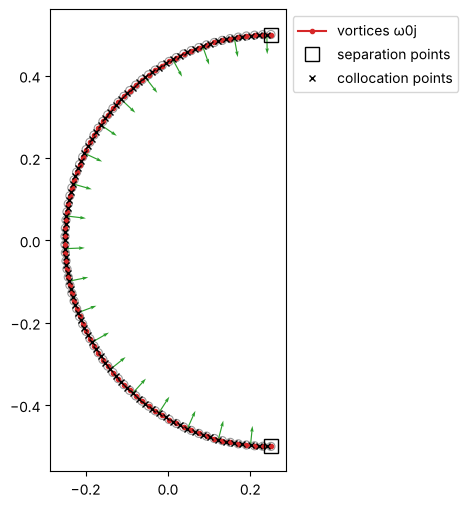

Γ0 = -1: ΣΓ = -1.000000000000, max|V·n| = 6.7e-16
Γ0 = +0: ΣΓ = +0.000000000000, max|V·n| = 5.0e-16
Γ0 = +1: ΣΓ = +1.000000000000, max|V·n| = 6.1e-16


In [2]:
c = Contour.semicircle(80)
plot_contour(c, every=4)
plt.show()
for g0 in (-1.0, 0.0, 1.0):
    sol = SteadySolution.solve(c, v_inf=(1, 0), gamma0=g0)
    print(f"Γ0 = {g0:+.0f}: ΣΓ = {sol.G.sum():+.12f}, max|V·n| = {sol.residual():.1e}")

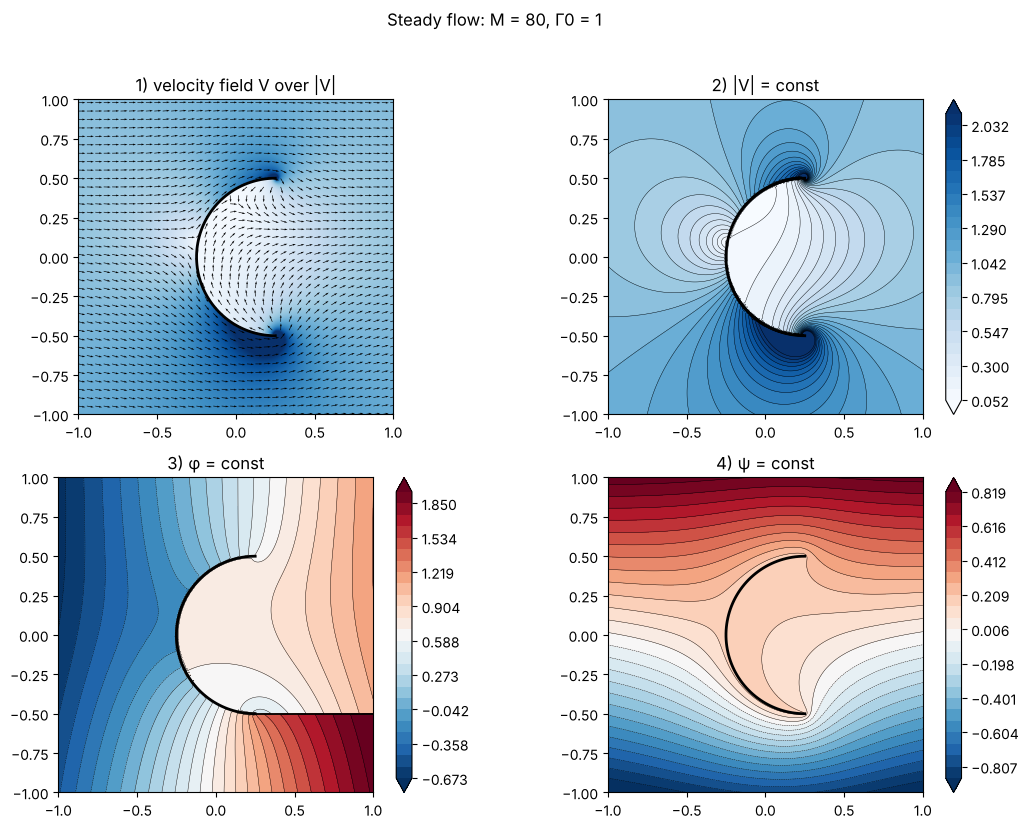

In [3]:
sol = SteadySolution.solve(c, v_inf=(1, 0), gamma0=1.0)
plot_four(sol, xlim=(-1, 1), ylim=(-1, 1), delta=c.h / 2, title="Steady flow: M = 80, Γ0 = 1")
plt.show()

## Unsteady flow: vortex shedding and the Kármán street ($\alpha = 0$)

In [4]:
sim = Simulation(Contour.semicircle(24)).run(80, every=1000)
print(sim.summary())

[    22 s] step 1000: t =  22.16 / 80, free vortices 1434, dt = 0.0210


[    87 s] step 2000: t =  40.63 / 80, free vortices 1317, dt = 0.0176


[   168 s] step 3000: t =  58.63 / 80, free vortices 1266, dt = 0.0177


[   249 s] step 4000: t =  76.73 / 80, free vortices 1262, dt = 0.0180


done in 264 s: 4180 steps, t = 80.01, free vortices 1229
{'Cx_mean': 1.3567247372949127, 'St': 0.24995563052048447}


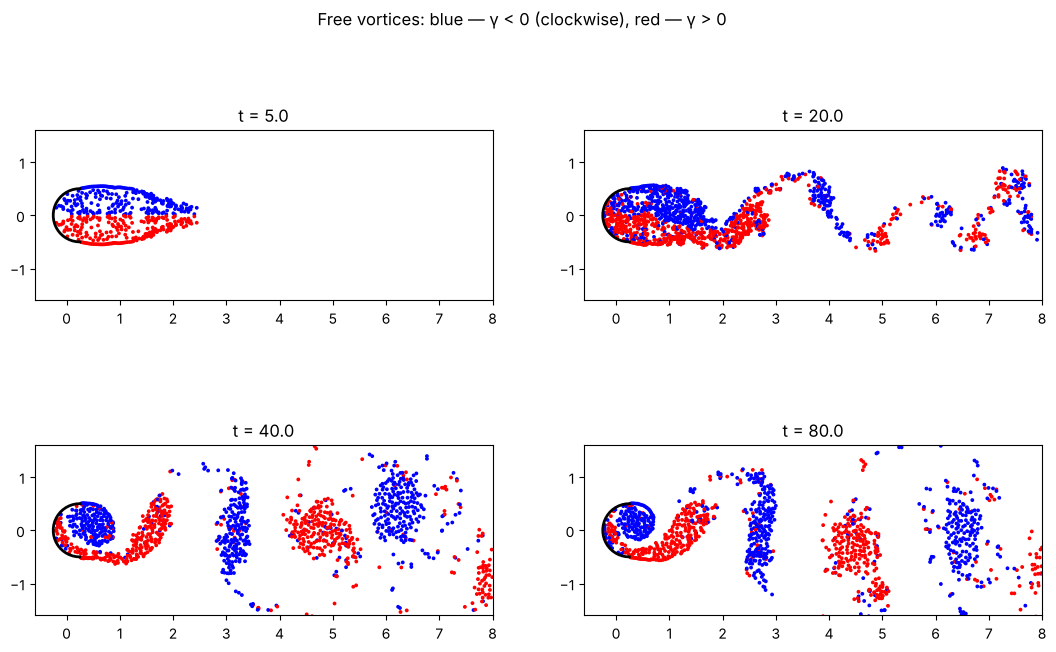

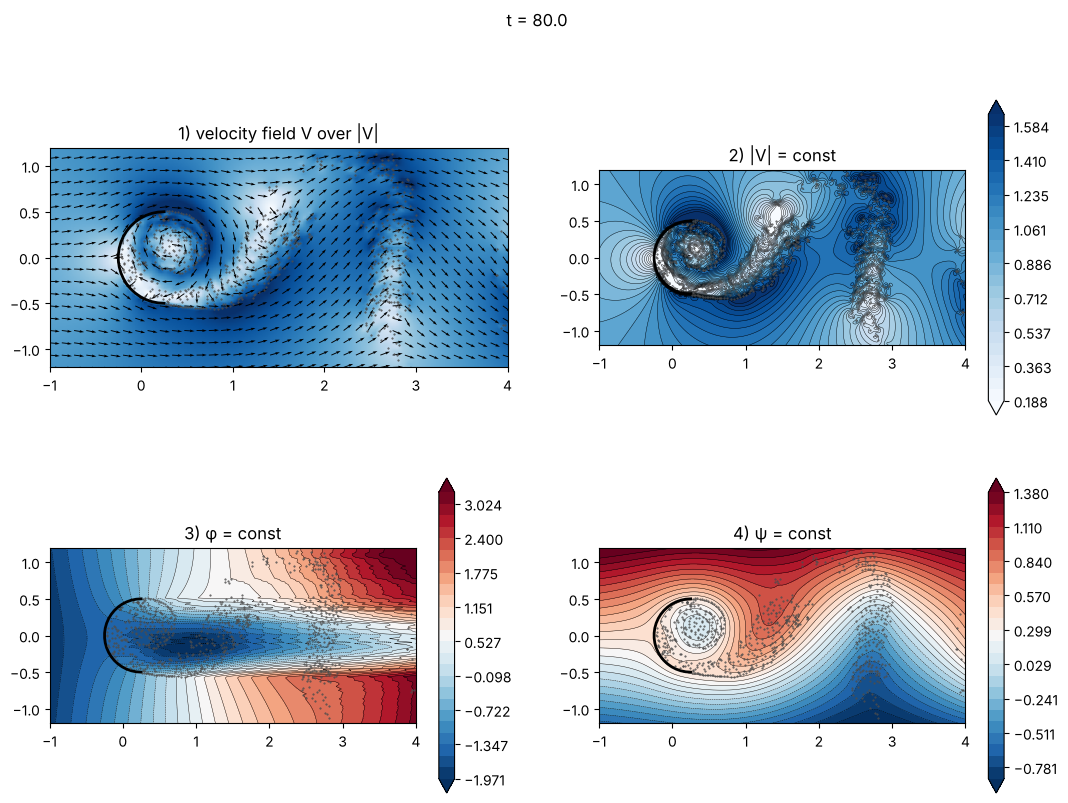

In [5]:
plot_wake(sim, [5, 20, 40, 80])
plt.show()
plot_four(sim, title=f"t = {sim.t:.1f}")
plt.show()

## Any shape: digit "5" with four separation points
Vortices that enter the cavity are absorbed by the contour (`absorb`).

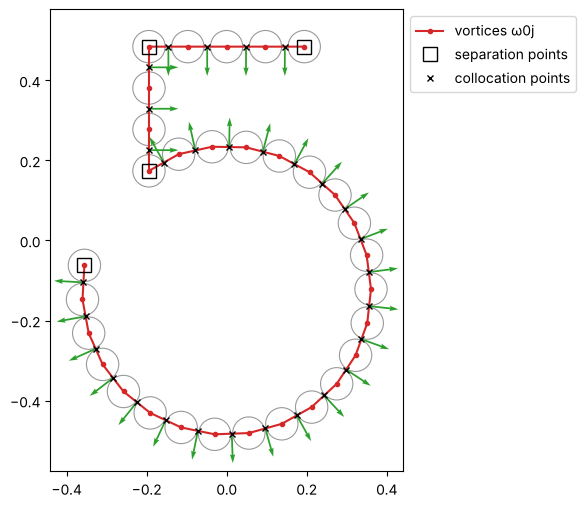

[    31 s] step 500: t =   8.33 / 20, free vortices 1750, dt = 0.0167


[   121 s] step 1000: t =  17.03 / 20, free vortices 2073, dt = 0.0164


done in 145 s: 1176 steps, t = 20.01, free vortices 2133


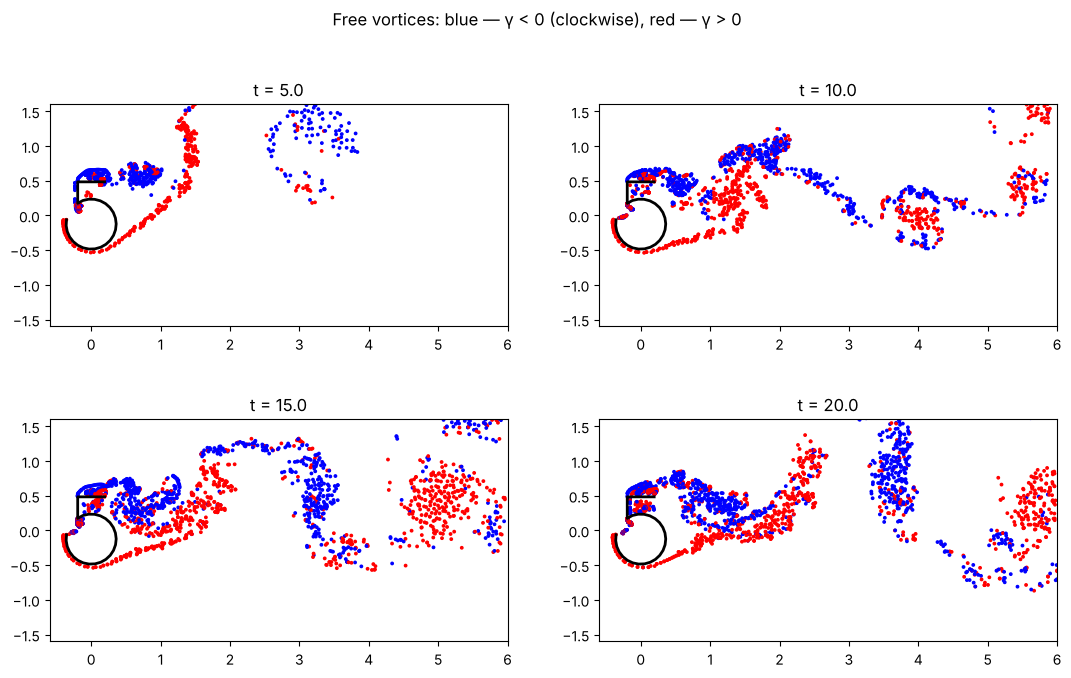

In [7]:
def digit_five(M=31):
    A, B, C = np.array([0.5, 1.25]), np.array([-0.5, 1.25]), np.array([-0.5, 0.45])
    OC, RC = np.array([0.0, -0.32]), 0.93
    a0, a1 = np.arctan2(C[1] - OC[1], C[0] - OC[0]), np.radians(170) - 2 * np.pi
    seg = lambda P, Q, n: P + np.linspace(0, 1, n + 1)[:, None] * (Q - P)
    L = [1.0, 0.8, RC * abs(a1 - a0)]
    n_ab, n_bc = round((M - 1) * L[0] / sum(L)), round((M - 1) * L[1] / sum(L))
    ang = np.linspace(a0, a1, (M - 1) - n_ab - n_bc + 1)
    P = np.vstack([seg(A, B, n_ab), seg(B, C, n_bc)[1:], (OC + RC * np.column_stack([np.cos(ang), np.sin(ang)]))[1:]])
    raw = Contour.from_points(P[:, 0], P[:, 1], separation=[0, n_ab, n_ab + n_bc, M - 1])
    c = raw.normalized()
    shift = np.array([(raw.x0.max() + raw.x0.min()) / 2, (raw.y0.max() + raw.y0.min()) / 2])
    cav = ((OC - shift) / raw.size, RC / raw.size - 3 * c.delta)   # cavity after normalisation
    return c, cav

five, cav = digit_five()
plot_contour(five); plt.show()
sim5 = Simulation(five, x_max=6, absorb=cav).run(20, every=500)
plot_wake(sim5, [5, 10, 15, 20]); plt.show()